# Day 2 - Decision Tree Regressor (Optional)

### This is an example of running the DecisionTreeRegressor model to complete a regression task on randomly generated data

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Generate some random data for modelling
np.random.seed(123)
number_of_instances = 100
predictor = np.arange(number_of_instances)
epsilon = np.random.uniform(-10,10, size=(number_of_instances,))
target = .4 * predictor + 3 + epsilon

In [2]:
# In order to use these arrays for regression modelling they need to be reshaped to 2D arrays
x = predictor.reshape(number_of_instances, 1)
y = target.reshape(number_of_instances, 1)

#### Splitting data into training and test sets
To understand model performance, dividing the dataset into a training set and a test set is a good strategy.

Let's split dataset by using function train_test_split(). You need to pass 3 parameters: features, target, and `test_size`. Additionally, you can use `random_state` to make the split reproducible.

In [0]:
# split data in training and test set
from sklearn.model_selection import train_test_split
# create training and testing vars
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=0)
print (x_train.shape, y_train.shape, x_test.shape, y_test.shape)

(80, 1) (80, 1) (20, 1) (20, 1)


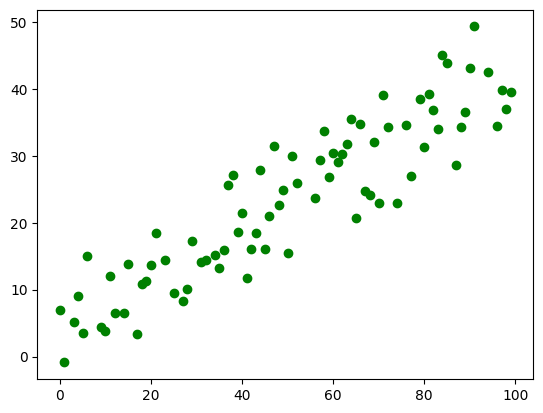

In [0]:
# plot data 
plt.scatter(x_train, y_train,  color='green')
plt.show()

#### Model Development and Prediction
First, import the DecisionTreeRegressor module.
Then, fit your model on the train set using fit() and perform prediction on the test set using predict().

A decision tree regressor repeatedly splits the feature space into regions, choosing each split to minimise the prediction error (by default, the squared error). For a new observation it predicts the mean target value of the training samples in the leaf it falls into.

In [0]:
from sklearn.tree import DecisionTreeRegressor
# Create object that stands for Decision Tree Regressor
model = DecisionTreeRegressor(random_state=42)
# Fit Decision Tree Regressor model
model.fit(x_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [0]:
# Generate predictions
y_pred = model.predict(x_test)

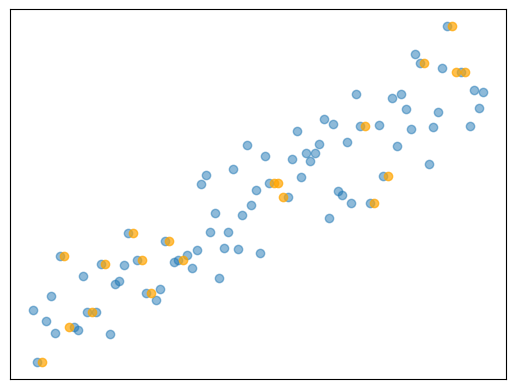

In [0]:
# Plot outputs
plt.scatter(x_train, y_train, color='tab:blue',  alpha = 0.5)
plt.scatter(x_test, y_pred, color='orange', alpha = 0.7)

plt.xticks(())
plt.yticks(())

plt.show()

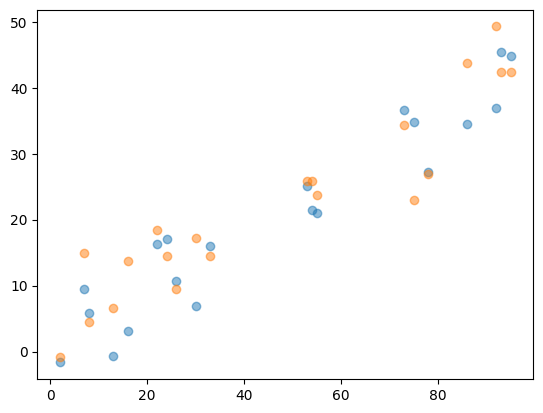

In [0]:
plt.scatter(x_test, y_test, alpha = 0.5)
plt.scatter(x_test, y_pred, alpha = 0.5)
plt.show()

In [0]:
# You can check the differences between results
y_pred = y_pred.reshape(y_test.shape)
np.concatenate([y_pred, y_test], axis = 1)

array([[ 9.45917828, 10.63577311],
       [43.83339994, 34.54795133],
       [-0.8772133 , -1.66297093],
       [23.74044422, 21.08241578],
       [22.92258413, 34.88863759],
       [42.46353833, 45.45095628],
       [13.75990811,  3.04983461],
       [34.34497944, 36.66832716],
       [25.86120257, 21.45527668],
       [42.46353833, 44.83403597],
       [25.86120257, 25.10136013],
       [49.30716964, 36.91829731],
       [26.97919288, 27.2614103 ],
       [ 6.57144489, -0.60644207],
       [15.01528397,  9.49659477],
       [17.21952248,  6.8420988 ],
       [18.38863588, 16.2891065 ],
       [14.42047021, 17.04886765],
       [14.41725527, 16.07370195],
       [ 4.44235036,  5.81863803]])

In [0]:
from sklearn.metrics import r2_score
# Check R^2
print("R^2 score:", r2_score(y_test, y_pred))

R^2 score: 0.8178015311577391


#### To get more details about model parameters please check sklearn [docs](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html)

## Your task: Decision Tree Regressor model for Advertising data

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.

### Build a prediction model

#### 1. Download (if it's not already downloaded) and load advertising data.

In [0]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv('advertising.csv', index_col=0)
df.head()
df.info()


#### 2. Split the dataset into labels and features.

In [0]:
X = df.drop(columns=["Sales"])
y = df["Sales"]


#### 3. Look at data and visualize them. Write what you observe.

In [0]:
df.describe()

sns.pairplot(df, vars=["TV", "Radio", "Newspaper", "Sales"])
plt.show()

corr = df.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()


In [0]:
plt.figure(figsize=(8, 5))
df['Sales'].hist(bins=20, edgecolor='black')
plt.title("Sales distribution")
plt.xlabel("Sales")
plt.ylabel("Count")
plt.show()


#### 4. Split the dataset into training and test sets.

In [0]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)


#### 5. Build Decision Tree Regressor model. Use 'Sales' as target variable.

In [0]:
model = DecisionTreeRegressor(max_depth=5, min_samples_leaf=5, random_state=42)
model.fit(X_train, y_train)
print("Model parameters:", model.get_params())


In [0]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances)


#### 6. Provide predictions for test set.

In [0]:
y_pred = model.predict(X_test)
print("Predicted Sales values:")
print(y_pred[:10])


#### 7. Evaluate the model (calculate R^2, MAE, MSE, RMSE).

In [0]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"R^2: {r2:.3f}")
print(f"MAE: {mae:.3f}")
print(f"MSE: {mse:.3f}")
print(f"RMSE: {rmse:.3f}")


# CONCLUSION
Compare the results of the Linear Regression and Decision Tree Regressor exercises.

Answer the following questions:
- Which model did better on Advertising.csv - LinearRegression or DecisionTreeRegressor?

  DecisionTreeRegressor did better on this dataset. It achieved a higher R^2 and lower MAE, MSE and RMSE than the linear regression model.

- How did you evaluate which was better?

  I used the same train/test split and compared the regression metrics on the test set: R^2, MAE, MSE, and RMSE.

- Why did this model do better?

  The relationship between advertising spend and sales is not purely linear. The decision tree can capture non-linear patterns and threshold effects between TV, radio, newspaper spend and sales.
